In [1]:
import sys
from pathlib import Path

src_path = Path.cwd().parent / 'src'

if str(src_path) not in sys.path:
    sys.path.insert(0, str(src_path))

from algorithm_creation import AlgorithmConfig, InferenceEngine, GlobalAligner, ImagePreprocessor, SatelliteMatcher
from model_inference import MatchingPipeline

In [2]:
import kornia
config = AlgorithmConfig(
    tile_size=512
)

feature_extractor = kornia.feature.LoFTR(pretrained='outdoor').to(config.device)
engine = InferenceEngine(feature_extractor, config)

 ### Demo 1: shift detection

* **Data source:** Sentinel-2 satellite images taken from the Copernicus Browser on **July 30, 2026**.
* **Setup:** we use two images of the same location. The second image is shifted slightly downwards from the starting point.
* **Expected result:** because of the vertical shift between the images, the matching lines (inliers) will appear as parallel diagonal or tilted lines connecting the identical points, clearly showing the direction and size of the offset.

/Users/aleksandralitvak/Documents/codes/python/Quantum Test Tasks/Computer vision. Sentinel-2 image matching/venv_cv/lib/python3.13/site-packages/rasterio/__init__.py:367: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, thread_safe=thread_safe, **kwargs)


 RESULT
  overlap confidence .............. 0.992  (HIGH — likely the same location)
  inliers ......................... 12240
  total matches ................... 12240
  alignment ....................... OK (aligned)


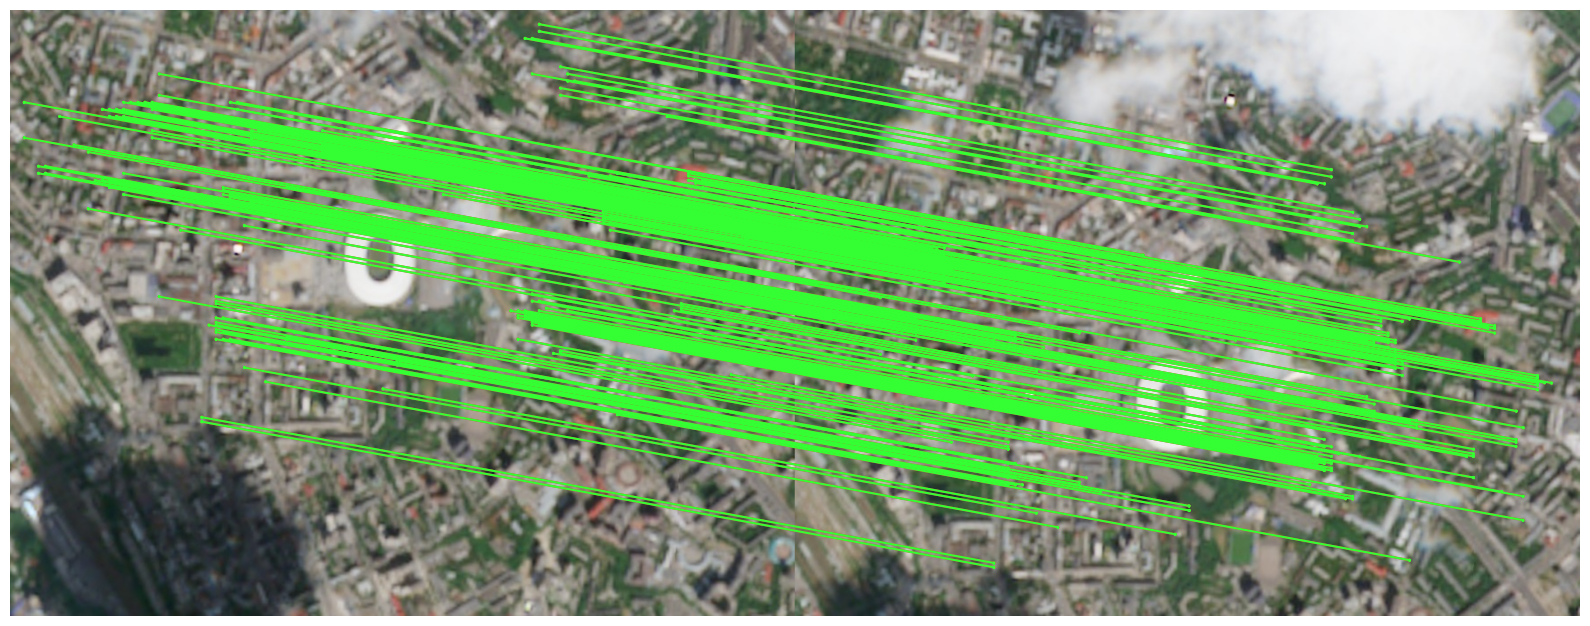

In [3]:
img0 = "../data/demo-1/2026-07-30-00_00_2026-07-30-23_59_Sentinel-2_L2A_True_color-2.jpg"
img1 = "../data/demo-1/2026-07-30-00_00_2026-07-30-23_59_Sentinel-2_L2A_True_color.jpg"

pipeline = MatchingPipeline(engine, config)

result = pipeline(img0, img1)

pipeline.draw_matches(
    matches=result, 
    show_outliers=True,    
    max_points=200,        
    strategy="best"   
)    

### Demo 2: cross-season(winter vs spring)

* **Data source:** Sentinel-2 satellite images from the Copernicus Browser of the same location from different seasons — **January 14, 2026** (winter, snow-covered) and **March 12, 2026** (spring, bare ground).
* **Setup:** no artificial shift is applied. The main challenge is the dramatic change in lighting, colors, and textures caused by weather and seasonal differences.
* **Expected result:** the model successfully finds structural matches and connects identical points between the snowy winter scene and the clear spring scene, proving its ability to handle cross-season satellite imagery.

 RESULT
  overlap confidence .............. 0.989  (HIGH — likely the same location)
  inliers ......................... 10107
  total matches ................... 10118
  alignment ....................... OK (aligned)


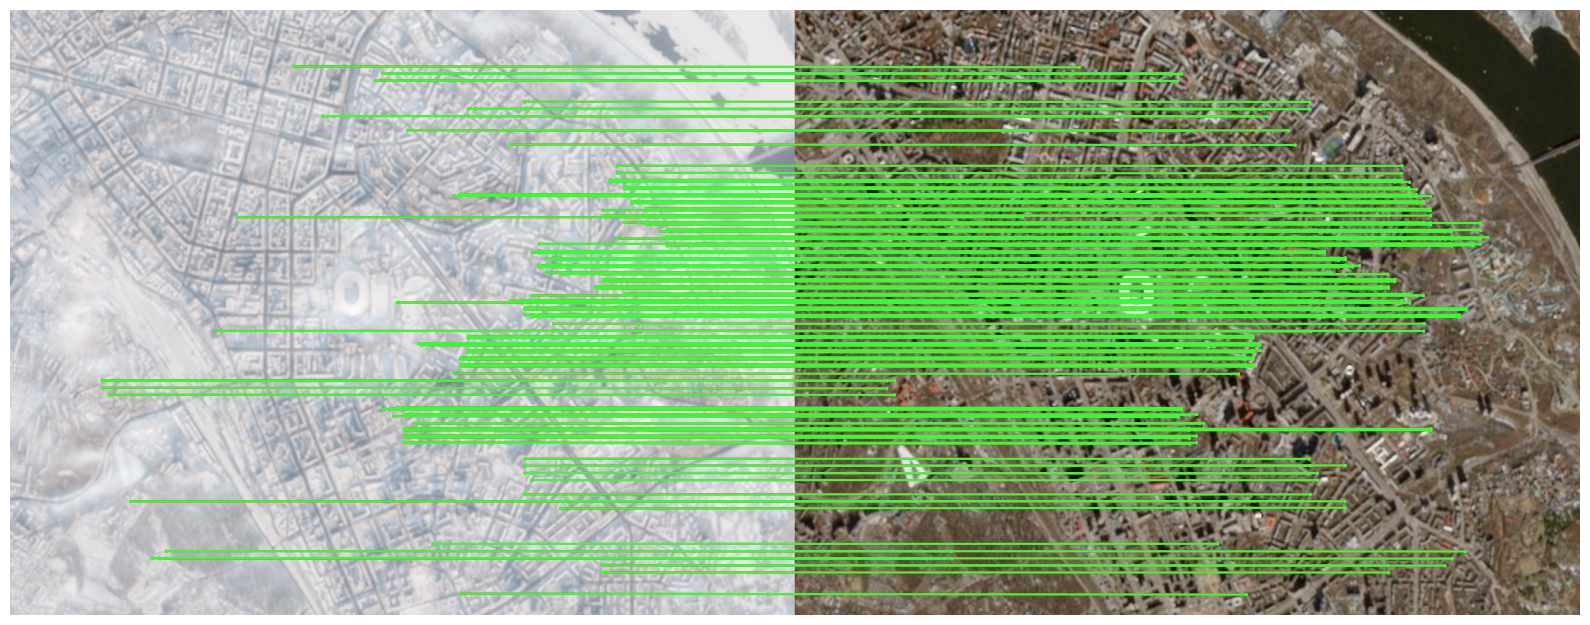

In [4]:
img2 = "../data/demo-2/2026-01-14-00_00_2026-01-14-23_59_Sentinel-2_L2A_True_color.jpg"
img3 = "../data/demo-2/2026-03-12-00_00_2026-03-12-23_59_Sentinel-2_L2A_True_color.jpg"

pipeline = MatchingPipeline(engine, config)

result = pipeline(img2, img3)

pipeline.draw_matches(
    matches=result, 
    show_outliers=True,    
    max_points=200,        
    strategy="best"   
)    

### Demo 3: one season - different location 

* **Data source:** Sentinel-2 satellite images from the Copernicus Browser of the different location from same seasons **January 14, 2026** (winter, snow-covered) 
* **Expected result:** the algorithm should correctly classify this as a NEGATIVE PAIR. Despite having similar winter textures (snow), the geographical locations are completely different. Geometric verification (RANSAC) should filter out any random matches, resulting in a very low number of inliers (below the threshold) and successfully preventing a False Positive.

/Users/aleksandralitvak/Documents/codes/python/Quantum Test Tasks/Computer vision. Sentinel-2 image matching/venv_cv/lib/python3.13/site-packages/rasterio/__init__.py:367: NotGeoreferencedWarning: Dataset has no geotransform, gcps, or rpcs. The identity matrix will be returned.
  dataset = DatasetReader(path, driver=driver, sharing=sharing, thread_safe=thread_safe, **kwargs)


 ALIGNMENT FAILED — 2026-01-14-00_00_2026-01-14-23_59_Sentinel-2_L2A_True_color-2.jpg vs 2026-01-14-00_00_2026-01-14-23_59_Sentinel-2_L2A_True_color.jpg
  The two images could not be co-registered; results are unreliable.
------------------------------------------------------------
  anchors selected ................ 2
  anchors matched ................. 0
  candidate tiles scored .......... 4
  candidates passing sanity ....... 0
  best inlier count ............... 0   (required: 15)
  pooled points ................... 0
  pooled inliers .................. 0
  reason .......................... no_anchor_matched
 RESULT
  overlap confidence .............. 0.001  (LOW — likely NOT the same location)
  inliers ......................... 0
  total matches ................... 5
  alignment ....................... FAILED (identity used, unreliable)


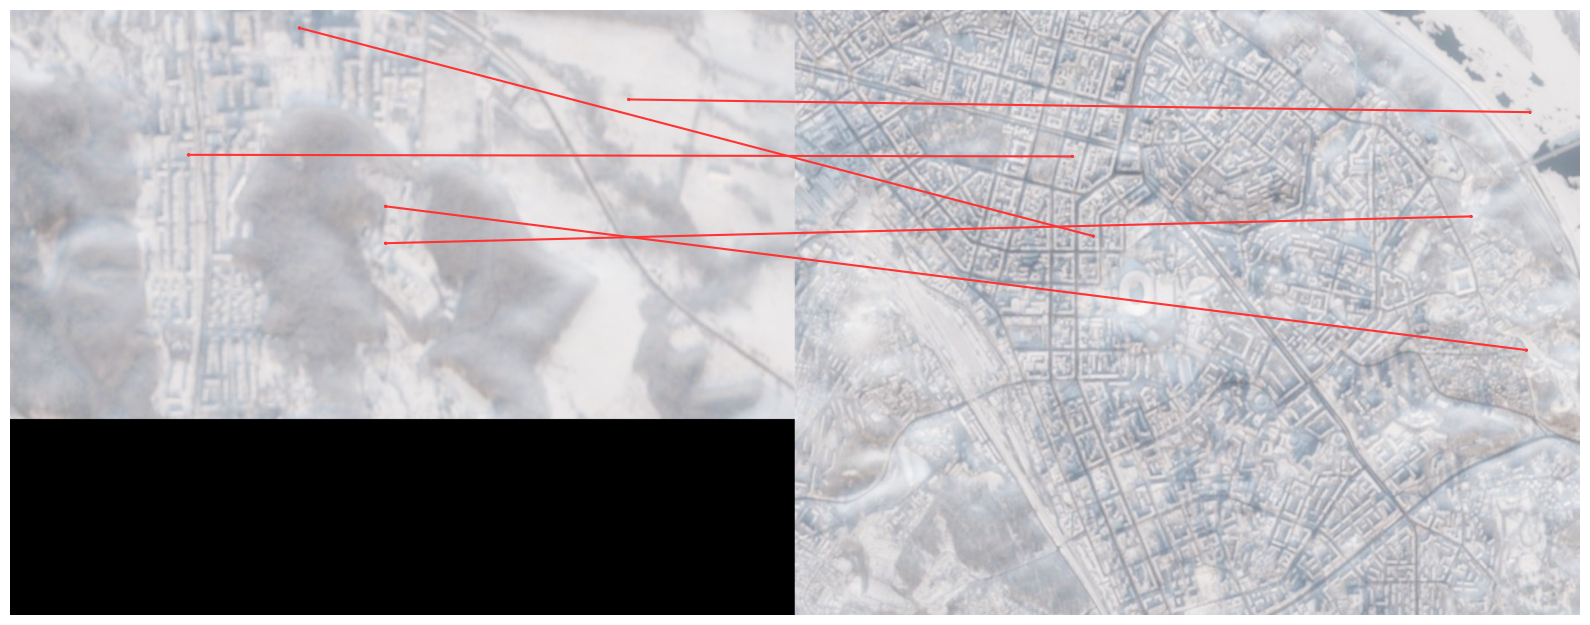

In [6]:
img4 = "../data/demo-3/2026-01-14-00_00_2026-01-14-23_59_Sentinel-2_L2A_True_color-2.jpg"
img5 = "../data/demo-3/2026-01-14-00_00_2026-01-14-23_59_Sentinel-2_L2A_True_color.jpg"

pipeline = MatchingPipeline(engine, config, output=True)

result = pipeline(img4, img5)

pipeline.draw_matches(
    matches=result, 
    show_outliers=True,    
    max_points=200,        
    strategy="best"   
)    